# 03 · Modelo de Cox / Cox proportional hazards

$$h(t \mid x) = h_0(t)\,\exp(\beta^\top x)$$

- $\exp(\beta_j)$ = **hazard ratio (HR)**: HR = 1,3 significa risco de saída 30% maior a cada instante,
  mantendo as demais variáveis constantes.
- Suposição-chave: **riscos proporcionais**, ou seja, o efeito de cada variável não muda com o tempo.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))  # works even without `pip install -e .`
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from turnover_survival import config, data, nonparametric, models, evaluation

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
T, E = config.DURATION_COL, config.EVENT_COL

df = data.load_clean()
print(f"{len(df)} employees | {df[E].sum()} left | {1 - df[E].mean():.1%} censored")

1116 employees | 560 left | 49.8% censored


## Matriz de modelagem / Design matrix

In [2]:
X = data.make_design_matrix(df)
train, test = data.split(X)
X.to_csv(config.DATA_PROCESSED / "design_matrix.csv", index=False)
print(X.shape, "| train", train.shape, "| test", test.shape)
X.head()

(1116, 44) | train (824, 44) | test (292, 44)


,age,extraversion,independ,selfcontrol,anxiety,novator,gender_m,industry_banks,industry_building,industry_consult,...,traffic_referal,coach_my head,coach_yes,head_gender_f,greywage_grey,way_car,way_foot,stag,event,profile_id
0,35.000,6.200,4.100,5.700,7.100,8.300,1.000,1.000,0.000,0.000,...,0.000,0.000,0.000,1.000,0.000,0.000,0.000,7.031,1,486
1,33.000,6.200,4.100,5.700,7.100,8.300,1.000,1.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,22.965,1,486
2,35.000,6.200,6.200,2.600,4.800,8.300,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,15.934,1,537
3,35.000,5.400,7.600,4.900,2.500,6.700,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,15.934,1,431
4,32.000,3.000,4.100,8.000,7.100,3.700,1.000,0.000,0.000,0.000,...,0.000,0.000,1.000,1.000,0.000,0.000,0.000,8.411,1,50


A categoria **mais frequente** de cada variável é a referência (omitida), portanto cada HR compara
aquela categoria com o grupo mais comum.

**`profile_id`**: ~41% das linhas repetem exatamente o perfil de personalidade de outra linha
(provavelmente a mesma pessoa em empregos diferentes). Essas linhas ficam **sempre do mesmo lado**
da divisão treino/teste e o Cox usa **erros-padrão robustos por cluster** (`cluster_col`).
A coluna não é covariável.

In [3]:
sizes = X.groupby(config.GROUP_COL).size()
print(f"{sizes.size} profiles for {len(X)} rows | rows in repeated profiles: {sizes[sizes > 1].sum()} | max group size: {sizes.max()}")
print("profiles in both train and test:", len(set(train[config.GROUP_COL]) & set(test[config.GROUP_COL])))

848 profiles for 1116 rows | rows in repeated profiles: 462 | max group size: 5
profiles in both train and test: 0


## Previsão vs inferência / Prediction vs inference
- **Previsão** (notebooks 05-06): o penalizer é ajustado por validação cruzada no treino.
- **Inferência** (hazard ratios e p-valores, este notebook): Cox **sem penalização**, ajustado em
  **todos os dados**. A penalização encolhe os coeficientes e invalida os erros-padrão robustos
  (o estimador sanduíche ignora o termo de penalização e passa a *subestimar* a incerteza).

In [4]:
cv = models.tune_cox_penalizer(train)
display(cv)
print(f"C-index spread across penalizers: {cv['cv_cindex_mean'].max() - cv['cv_cindex_mean'].min():.4f} "
      f"(fold std ≈ {cv['cv_cindex_std'].mean():.3f}) -> the choice barely matters for prediction")

,penalizer,cv_cindex_mean,cv_cindex_std
0,0.500,0.586,0.019
1,0.050,0.585,0.025
2,0.100,0.585,0.023
3,0.010,0.585,0.027
4,0.001,0.585,0.027


C-index spread across penalizers: 0.0010 (fold std ≈ 0.024) -> the choice barely matters for prediction


## Ajuste para inferência / Inference fit

In [5]:
cph = models.fit_cox(X, penalizer=0.0)  # unpenalised, cluster-robust SEs by profile_id
print(f"concordance (in-sample): {cph.concordance_index_:.3f}")
hr = models.hazard_ratio_table(cph)
hr

concordance (in-sample): 0.654


,HR,HR_lower_95,HR_upper_95,p,significant
covariate,,,,,
profession_manage,2.737,1.799,4.163,0.000,True
industry_building,2.360,1.538,3.623,0.000,True
profession_commercial,2.212,1.257,3.895,0.006,True
industry_banks,2.212,1.563,3.131,0.000,True
industry_consult,1.893,1.227,2.918,0.004,True
profession_marketing,1.730,1.091,2.745,0.020,True
industry_etc,1.666,1.201,2.311,0.002,True
greywage_grey,1.626,1.240,2.133,0.000,True
profession_consult,1.616,0.925,2.822,0.092,False


### Erros-padrão robustos vs ingênuos / Robust vs naive standard errors
Mesmo modelo, mas tratando cada linha como pessoa independente: quantos efeitos só pareciam
significativos por causa das linhas repetidas?

In [6]:
naive = models.hazard_ratio_table(models.fit_cox(X, penalizer=0.0, robust=False))
cmp = hr[["HR", "p"]].join(naive[["p"]], rsuffix="_naive")
cmp["changed"] = (cmp["p"] < 0.05) != (cmp["p_naive"] < 0.05)
print(f"significant (robust): {(cmp['p'] < 0.05).sum()} | significant (naive): {(cmp['p_naive'] < 0.05).sum()}")
cmp[cmp["changed"] | (cmp["p"] < 0.05)]

significant (robust): 17 | significant (naive): 17


,HR,p,p_naive,changed
covariate,,,,
profession_manage,2.737,0.000,0.000,False
industry_building,2.360,0.000,0.000,False
profession_commercial,2.212,0.006,0.006,False
industry_banks,2.212,0.000,0.000,False
industry_consult,1.893,0.004,0.001,False
profession_marketing,1.730,0.020,0.022,False
industry_etc,1.666,0.002,0.003,False
greywage_grey,1.626,0.000,0.000,False
industry_state,1.589,0.045,0.030,False


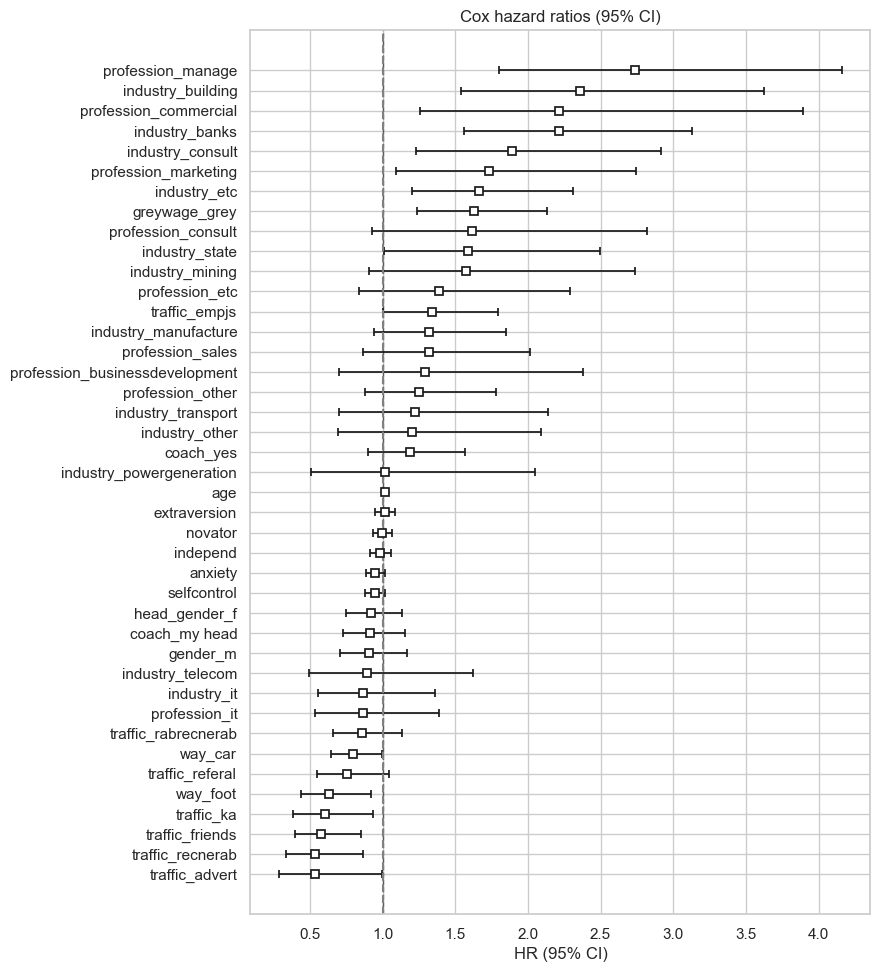

In [7]:
fig, ax = plt.subplots(figsize=(8, max(5, 0.28 * len(hr))))
cph.plot(hazard_ratios=True, ax=ax)
ax.axvline(1, c="grey", ls="--")
ax.set_title("Cox hazard ratios (95% CI)")
fig.savefig(config.FIGURES_DIR / "03_cox_hr.png", dpi=120, bbox_inches="tight")

## Verificação de riscos proporcionais / Proportional-hazards check

In [8]:
ph = models.ph_assumption_table(cph, X)
ph[ph["p"] < 0.05]

,test_statistic,p,-log2(p)
traffic_recnerab,6.475,0.011,6.515
traffic_referal,5.375,0.020,5.613
novator,4.421,0.035,4.816
profession_sales,4.171,0.041,4.604
industry_etc,4.121,0.042,4.561


Covariáveis com p < 0,05 violam a suposição de PH. Opções:
1. **Estratificar** pela variável (`strata=[...]`): ela ganha sua própria $h_0(t)$, mas sem HR;
2. Incluir **interação com o tempo** (modelo com covariável tempo-dependente);
3. Migrar para um modelo **AFT** (notebook 04), que não assume PH.

A célula abaixo traz o diagnóstico detalhado com recomendações; use `show_plots=True` para ver os resíduos de Schoenfeld.

In [9]:
# show_plots=True draws Schoenfeld-residual plots for every flagged covariate (slow but useful)
cph.check_assumptions(X, p_value_threshold=0.05, show_plots=False, advice=True);

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See link [A] below for a full example.



<lifelines.StatisticalResult: proportional_hazard_test>
 null_distribution = chi squared
degrees_of_freedom = 1
             model = <lifelines.CoxPHFitter: fitted with 1116 total observations, 556 right-censored observations>
         test_name = proportional_hazard_test

---
                                     test_statistic    p  -log2(p)
age                            km              0.01 0.91      0.14
                               rank            0.00 0.94      0.08
anxiety                        km              1.37 0.24      2.04
                               rank            0.97 0.32      1.63
coach_my head                  km              1.86 0.17      2.53
                               rank            3.18 0.07      3.74
coach_yes                      km              0.08 0.77      0.38
                               rank            0.14 0.70      0.51
extraversion                   km              3.82 0.05      4.30
                               rank            2.95 0.09      3.54
gender_m                       km              0.00 0.96      0.06
                               rank            0.01 0.94      0.09
greywage_grey                  km              0.04 0.84      0.25
                               rank            0.01 0.92      0.11
head_gender_f                  km              0.00 0.98      0.03
                               rank            0.06 0.81      0.30
independ                       km              0.07 0.79      0.33
                               rank            0.05 0.83      0.27
industry_banks                 km              0.00 0.94      0.08
                               rank            0.00 0.97      0.04
industry_building              km              0.01 0.93      0.11
                               rank            0.00 0.97      0.04
industry_consult               km              0.13 0.72      0.47
                               rank            0.03 0.86      0.22
industry_etc                   km              3.67 0.06      4.17
                               rank            4.12 0.04      4.56
industry_it                    km              0.11 0.75      0.42
                               rank            0.27 0.60      0.73
industry_manufacture           km              1.23 0.27      1.90
                               rank            1.20 0.27      1.87
industry_mining                km              0.50 0.48      1.06
                               rank            0.33 0.56      0.83
industry_other                 km              0.56 0.45      1.14
                               rank            0.51 0.47      1.08
industry_powergeneration       km              0.23 0.63      0.66
                               rank            0.06 0.81      0.31
industry_state                 km              0.02 0.90      0.15
                               rank            0.19 0.66      0.59
industry_telecom               km              0.39 0.53      0.91
                               rank            0.61 0.43      1.20
industry_transport             km              0.53 0.47      1.09
                               rank            0.66 0.42      1.26
novator                        km              3.70 0.05      4.20
                               rank            4.42 0.04      4.82
profession_businessdevelopment km              2.35 0.13      2.99
                               rank            2.08 0.15      2.74
profession_commercial          km              0.15 0.70      0.52
                               rank            0.42 0.52      0.95
profession_consult             km              1.35 0.24      2.03
                               rank            2.26 0.13      2.91
profession_etc                 km              0.02 0.89      0.16
                               rank            0.01 0.91      0.13
profession_it                  km              0.48 0.49      1.03
                               rank            0.30 0.59      0.77
profession_manage              km    



1. Variable 'extraversion' failed the non-proportional test: p-value is 0.0507.

   Advice 1: the functional form of the variable 'extraversion' might be incorrect. That is, there
may be non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specify a functional form.

   Advice 2: try binning the variable 'extraversion' using pd.cut, and then specify it in
`strata=['extraversion', ...]` in the call in `.fit`. See documentation in link [B] below.

   Advice 3: try adding an interaction term with your time variable. See documentation in link [C]
below.


2. Variable 'novator' failed the non-proportional test: p-value is 0.0355.

   Advice 1: the functional form of the variable 'novator' might be incorrect. That is, there may be
non-linear terms missing. The proportional hazard test used is very sensitive to incorrect
functional forms. See documentation in link [D] below on how to specif

## Curvas ajustadas por perfil / Partial effects

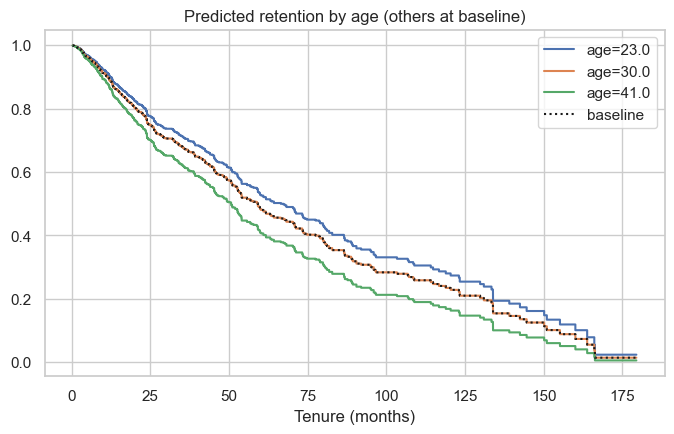

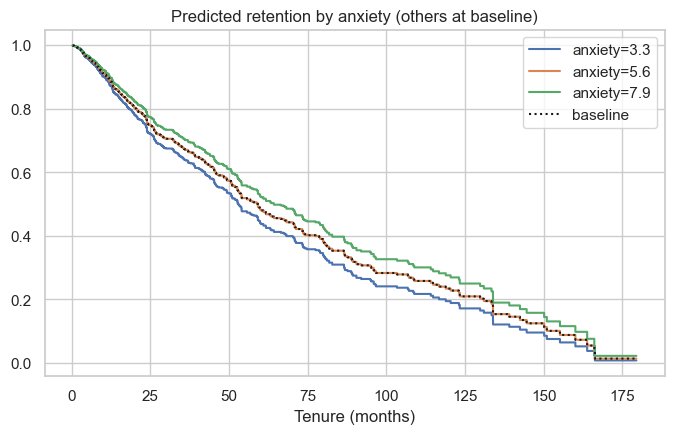

In [10]:
for cov in ["age", "anxiety"]:
    if cov in X:
        ax = cph.plot_partial_effects_on_outcome(cov, values=np.percentile(X[cov], [10, 50, 90]).round(1), figsize=(8, 4.5))
        ax.set(title=f"Predicted retention by {cov} (others at baseline)", xlabel="Tenure (months)")
        plt.savefig(config.FIGURES_DIR / f"03_partial_{cov}.png", dpi=120, bbox_inches="tight")

### Conclusões / Takeaways
> _Preencha após rodar com os dados reais. / Fill in after running on the real data._